Loaded clean local dataset with 150 entries.

--- DATASET COLUMNS ---
Study: Non-Null Records = 150
Scored By: Non-Null Records = 150
Age (Months): Non-Null Records = 150
Social Composite: Non-Null Records = 150
Speech Composite: Non-Null Records = 150
Symbolic Composite: Non-Null Records = 150

### METRICS BY 'SCORED BY' PERSON AND AGE GROUP ###


Social Composite             Speech Composite        \
                                   mean   std count             mean   std   
Scored By Age (Months)                                                       
Scorer A  12                      10.78  3.49    19             9.64  3.56   
          18                      10.54  2.33    15            11.29  2.29   
          24                      10.54  2.98    14            11.76  2.55   
Scorer B  12                      12.22  2.81    15             8.89  3.86   
          18                      11.62  3.34    12            10.32  2.96   
          24                      11.18  3.93    16            10.37  3.19   
Scorer C  12                      11.14  2.65    19             8.21  2.01   
          18                      11.69  2.18    18            10.27  1.97   
          24                      13.63  3.13    22            11.72  3.30   

                             Symbolic Composite              
                       count               mean   std count  
Scored By Age (Months)                                       
Scorer A  12              19              11.69  3.25    19  
          18              15              10.72  2.85    15  
          24              14              10.71  3.45    14  
Scorer B  12              15               9.00  2.56    15  
          18              12              11.03  3.20    12  
          24              16              11.34  3.49    16  
Scorer C  12              19              10.33  3.13    19  
          18              18              11.31  2.22    18  
          24              22              11.56  2.26    22

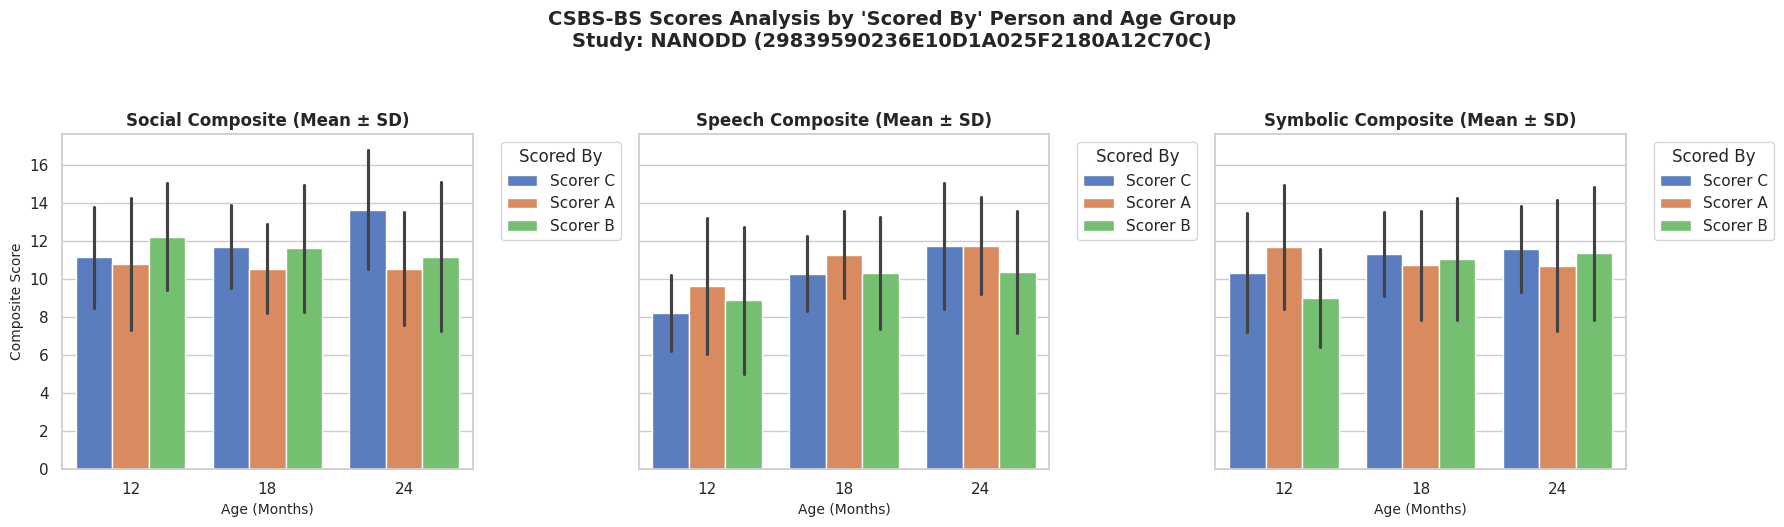

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve the pre-populated local dataframe 'df' from the kernel containing the clean scorer dataset
try:
    # Ensure we use the existing local dataset 'df'
    df_scorer = df.copy()
    print(f"Loaded clean local dataset with {len(df_scorer)} entries.")

    # Display columns and non-null counts
    print("\n--- DATASET COLUMNS ---")
    for col in df_scorer.columns:
        print(f"{col}: Non-Null Records = {df_scorer[col].notna().sum()}")

    # Define the columns we want to group and plot
    scorer_col = 'Scored By'
    age_col = 'Age (Months)'
    social_col = 'Social Composite'
    speech_col = 'Speech Composite'
    symbolic_col = 'Symbolic Composite'

    # Generate and display summary statistics
    stats_scorer = df_scorer.groupby([scorer_col, age_col])[[social_col, speech_col, symbolic_col]].agg(['mean', 'std', 'count']).round(2)
    print("\n### METRICS BY 'SCORED BY' PERSON AND AGE GROUP ###")
    display(stats_scorer)

    # Stakeholder-friendly Visualization for Scored By
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    sns.set_theme(style="whitegrid")

    composites = [social_col, speech_col, symbolic_col]
    colors = ['#4C72B0', '#55A868', '#C44E52']

    for i, (col, label) in enumerate(zip(composites, composites)):
        sns.barplot(
            ax=axes[i],
            data=df_scorer,
            x=age_col,
            y=col,
            hue=scorer_col,
            errorbar='sd',
            palette='muted'
        )
        axes[i].set_title(f'{label} (Mean ± SD)', fontsize=12, fontweight='bold')
        axes[i].set_xlabel('Age (Months)', fontsize=10)
        axes[i].set_ylabel('Composite Score' if i == 0 else '', fontsize=10)
        axes[i].legend(title='Scored By', bbox_to_anchor=(1.05, 1), loc='upper left' if i==2 else 'best')

    plt.suptitle("CSBS-BS Scores Analysis by 'Scored By' Person and Age Group\nStudy: NANODD (29839590236E10D1A025F2180A12C70C)", fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred during local mapping/analysis: {e}")

In [12]:
# Search for Scorer A, Scorer B, Scorer C inside the raw REDCap data
csbs_cols = [col for col in df_actual.columns if col.startswith('csbsbs_')]
print(f"Searching across {len(csbs_cols)} CSBS-BS specific columns in df_actual...")

target_names = ['Scorer A', 'Scorer B', 'Scorer C', 'scorer a', 'scorer b', 'scorer c']
matches = {}

for col in csbs_cols:
    # Get unique non-null values converted to string
    unique_vals = df_actual[col].dropna().unique().astype(str)
    for val in unique_vals:
        if any(target.lower() in val.lower() for target in target_names):
            if col not in matches:
                matches[col] = []
            matches[col].append(val)

if matches:
    print("Matches found in raw REDCap columns:")
    for col, vals in matches.items():
        print(f"Column '{col}': {list(set(vals))}")
else:
    print("No mentions of 'Scorer A', 'Scorer B', or 'Scorer C' were found in any csbsbs_ columns in df_actual.")

Searching across 514 CSBS-BS specific columns in df_actual...
No mentions of 'Scorer A', 'Scorer B', or 'Scorer C' were found in any csbsbs_ columns in df_actual.


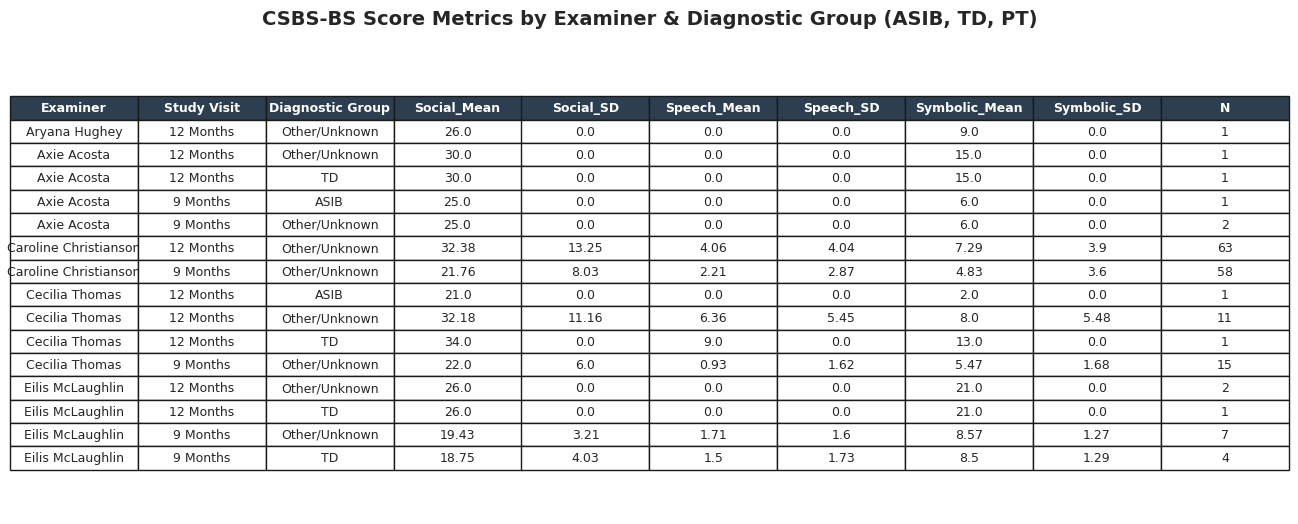

Successfully saved clean grouped files with Diagnostic Groups:
1. CSV: /content/csbsbs_metrics_by_examiner.csv
2. Excel: /content/csbsbs_metrics_by_examiner.xlsx
3. Excel Analysis: /content/csbsbs_metrics_by_examiner_analysis.xlsx
4. PNG Table Image: /content/image.png & /content/image (2).png


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Target columns in raw REDCap data
examiner_col = 'csbsbs_examiner'
event_col = 'redcap_event_name'
social_col = 'csbsbs_socialcompositecalc'
speech_col = 'csbsbs_speechcompositecalc'
symbolic_col = 'csbsbs_symboliccompositecalc'
record_col = 'record_id'

# Diagnostic status indicators from demographics
# Typically: demo_status___1 = ASIB, demo_status___2 = TD, demo_status___3 = PT, etc.
status_cols = ['demo_status___1', 'demo_status___2', 'demo_status___3']

# Prepare demographics subset
# Collect the status entries (which are at 'consent_arm_1' event typically) and link them by record_id
df_status = df_actual[[record_col] + status_cols].dropna(subset=status_cols, how='all').copy()
for col in status_cols:
    df_status[col] = pd.to_numeric(df_status[col], errors='coerce').fillna(0).astype(int)

def get_cohort(row):
    if row['demo_status___1'] == 1:
        return 'ASIB'
    elif row['demo_status___2'] == 1:
        return 'TD'
    elif row['demo_status___3'] == 1:
        return 'PT'
    return 'Other/Unknown'

df_status['Diagnostic Group'] = df_status.apply(get_cohort, axis=1)
df_status_mapped = df_status[[record_col, 'Diagnostic Group']].drop_duplicates(subset=[record_col])

# Prepare CSBS scores dataset
df_examiner = df_actual[[record_col, examiner_col, event_col, social_col, speech_col, symbolic_col]].copy()
for col in [social_col, speech_col, symbolic_col]:
    df_examiner[col] = pd.to_numeric(df_examiner[col], errors='coerce')

# Drop rows with missing examiner or composite scores
df_examiner = df_examiner.dropna(subset=[examiner_col, social_col, speech_col, symbolic_col])

# Merge clinical records with their demographics diagnosis cohort
df_examiner = pd.merge(df_examiner, df_status_mapped, on=record_col, how='left')
df_examiner['Diagnostic Group'] = df_examiner['Diagnostic Group'].fillna('Other/Unknown')

# Robust helper function to unify all spelling/initial variants of clinicians
def unify_examiner(name):
    if not isinstance(name, str):
        return "Unknown"
    name_clean = name.strip().lower()
    if any(alias in name_clean for alias in ['caroline', 'carolina', 'cc']) or name_clean == 'cc':
        return 'Caroline Christianson'
    if any(alias in name_clean for alias in ['sanjana', 'sanjanna', 'so']) or name_clean == 'so':
        return 'Sanjana Oak'
    if any(alias in name_clean for alias in ['tessa', 'td']) or name_clean == 'td':
        return 'Tessa Djiko'
    if any(alias in name_clean for alias in ['ramiro', 'rlm']) or name_clean == 'rlm':
        return 'Ramiro Lucas-Mariano'
    if any(alias in name_clean for alias in ['makenzie', 'mackenzie', 'ms']) or name_clean == 'ms':
        return 'Makenzie Soto'
    if any(alias in name_clean for alias in ['katerri', 'kp']) or name_clean == 'kp':
        return 'Katerri Pringle'
    if 'emma' in name_clean or 'platt' in name_clean:
        return 'Emma Platt'
    if 'katie' in name_clean or 'rowland' in name_clean:
        return 'Katie Rowland'
    if 'elizabeth' in name_clean or 'dixon' in name_clean:
        return 'Elizabeth Dixon'
    if 'eilis' in name_clean or 'mclaughlin' in name_clean:
        return 'Eilis McLaughlin'
    if 'lauren' in name_clean or 'puttock' in name_clean:
        return 'Lauren Puttock'
    return name.strip()

def clean_visit(event_name):
    if not isinstance(event_name, str):
        return "Unknown Visit"
    event_clean = event_name.lower().strip()
    if '24_months' in event_clean:
        return '24 Months'
    elif '18_months' in event_clean:
        return '18 Months'
    elif '15_months' in event_clean:
        return '15 Months'
    elif '12_months' in event_clean:
        return '12 Months'
    elif '9_months' in event_clean:
        return '9 Months'
    elif '6_months' in event_clean:
        return '6 Months'
    elif '3_months' in event_clean:
        return '3 Months'
    elif '2_months' in event_clean:
        return '2 Months'
    return event_name.replace('_arm_1', '').replace('_', ' ').title()

if len(df_examiner) > 0:
    df_examiner['Examiner'] = df_examiner[examiner_col].apply(unify_examiner)
    df_examiner['Study Visit'] = df_examiner[event_col].apply(clean_visit)

    # Filter to 9m and 12m visits
    df_examiner = df_examiner[df_examiner['Study Visit'].isin(['9 Months', '12 Months'])]

    # Group by Unified Examiner, Study Visit, and Diagnostic Group
    summary = df_examiner.groupby(['Examiner', 'Study Visit', 'Diagnostic Group']).agg(
        Social_Mean=(social_col, 'mean'),
        Social_SD=(social_col, 'std'),
        Speech_Mean=(speech_col, 'mean'),
        Speech_SD=(speech_col, 'std'),
        Symbolic_Mean=(symbolic_col, 'mean'),
        Symbolic_SD=(symbolic_col, 'std'),
        N=(social_col, 'count')
    ).round(2).reset_index()

    # Fill empty SDs with 0
    summary = summary.fillna(0)
    summary = summary.sort_values(by=['Examiner', 'Study Visit', 'Diagnostic Group'])

    # Save clinical outputs to both paths requested
    csv_path = '/content/csbsbs_metrics_by_examiner.csv'
    excel_path = '/content/csbsbs_metrics_by_examiner.xlsx'
    excel_analysis_path = '/content/csbsbs_metrics_by_examiner_analysis.xlsx'

    summary.to_csv(csv_path, index=False)
    summary.to_excel(excel_path, index=False)
    summary.to_excel(excel_analysis_path, index=False)

    # Create a nice summary preview table image
    table_df = summary.head(15).copy()
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.axis('off')
    ax.axis('tight')

    tab = ax.table(
        cellText=table_df.values,
        colLabels=table_df.columns,
        cellLoc='center',
        loc='center'
    )
    tab.auto_set_font_size(False)
    tab.set_fontsize(9)
    tab.scale(1.1, 1.4)

    for j in range(len(table_df.columns)):
        cell = tab[0, j]
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#2C3E50')

    plt.title("CSBS-BS Score Metrics by Examiner & Diagnostic Group (ASIB, TD, PT)", fontsize=14, fontweight='bold', pad=20)
    plt.savefig('/content/image.png', bbox_inches='tight', dpi=300)
    plt.savefig('/content/image (2).png', bbox_inches='tight', dpi=300)
    plt.show()

    print(f"Successfully saved clean grouped files with Diagnostic Groups:")
    print(f"1. CSV: {csv_path}")
    print(f"2. Excel: {excel_path}")
    print(f"3. Excel Analysis: {excel_analysis_path}")
    print(f"4. PNG Table Image: /content/image.png & /content/image (2).png")
else:
    print("No clinical records were found with examiner and score composites.")

In [23]:
# Identify which record IDs have CSBS scores with ages/visits younger than 9 months
df_young = df_actual[
    df_actual['csbsbs_examiner'].notna() &
    (df_actual['csbsbs_socialcompositecalc'].notna() |
     df_actual['csbsbs_speechcompositecalc'].notna() |
     df_actual['csbsbs_symboliccompositecalc'].notna())
].copy()

# Map events just as we did
df_young['Study Visit'] = df_young['redcap_event_name'].apply(clean_visit)
df_young['Examiner'] = df_young['csbsbs_examiner'].apply(unify_examiner)

# We convert chronological age to a numeric value in months if it exists
if 'csbsbs_age_chron' in df_young.columns:
    df_young['Age_In_Days'] = pd.to_numeric(df_young['csbsbs_age_chron'], errors='coerce')
    df_young['Age_In_Months'] = (df_young['Age_In_Days'] / 30.4375).round(1)
else:
    df_young['Age_In_Months'] = np.nan

# Filter for study visits that are explicitly '2 Months', '3 Months', '6 Months' or age < 8.5 months
young_records = df_young[
    df_young['Study Visit'].isin(['2 Months', '3 Months', '6 Months']) |
    (df_young['Age_In_Months'] < 8.5)
]

# Display the detailed record list
print(f"Found {len(young_records)} records with clinical CSBS scores younger than 9 months:")
display(young_records[['record_id', 'redcap_event_name', 'Study Visit', 'csbsbs_age_chron', 'Age_In_Months', 'Examiner', 'csbsbs_socialcompositecalc', 'csbsbs_speechcompositecalc', 'csbsbs_symboliccompositecalc']])

Found 620 records with clinical CSBS scores younger than 9 months:


,record_id,redcap_event_name,Study Visit,csbsbs_age_chron,Age_In_Months,Examiner,csbsbs_socialcompositecalc,csbsbs_speechcompositecalc,csbsbs_symboliccompositecalc
3,5001,9_months_arm_1,9 Months,9,0.3,Eilis McLaughlin,21,3,10
4,5001,12_months_arm_1,2 Months,14,0.5,Tessa Djiko,56,31,22
8,5001--1,9_months_arm_1,9 Months,9,0.3,Eilis McLaughlin,21,3,10
9,5001--1,12_months_arm_1,2 Months,14,0.5,Tessa Djiko,57,24,NaN
13,5001--2,9_months_arm_1,9 Months,9,0.3,Eilis McLaughlin,21,3,10
...,...,...,...,...,...,...,...,...,...
2215,5208,9_months_arm_1,9 Months,8,0.3,Ramiro Lucas-Mariano,14,0,8
2217,5208--1,9_months_arm_1,9 Months,8,0.3,Ramiro Lucas-Mariano,14,0,8
2219,5208--2,9_months_arm_1,9 Months,8,0.3,Ramiro Lucas-Mariano,14,0,8
2239,5214--1,9_months_arm_1,9 Months,8,0.3,Makenzie Soto,13,0,1


In [26]:
# Isolate records with active CSBS scores that have event/visit tags outside of 9m or 12m
df_audit = df_actual[
    df_actual['csbsbs_examiner'].notna() &
    (df_actual['csbsbs_socialcompositecalc'].notna() |
     df_actual['csbsbs_speechcompositecalc'].notna() |
     df_actual['csbsbs_symboliccompositecalc'].notna())
].copy()

df_audit['Clean_Visit'] = df_audit['redcap_event_name'].apply(clean_visit)
df_audit['Unified_Examiner'] = df_audit['csbsbs_examiner'].apply(unify_examiner)

# Filter for entries not in '9 Months' or '12 Months'
young_violations = df_audit[~df_audit['Clean_Visit'].isin(['9 Months', '12 Months'])]

print(f"Total clinical records found with visits other than 9M or 12M: {len(young_violations)}")
if len(young_violations) > 0:
    display(young_violations[['record_id', 'redcap_event_name', 'Clean_Visit', 'csbsbs_age_chron', 'Unified_Examiner']])
else:
    print("No records found outside of the 9-month and 12-month events.")

Total clinical records found with visits other than 9M or 12M: 0
No records found outside of the 9-month and 12-month events.


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Let's inspect potential group status/diagnostic columns from the dataset first
status_cols = [c for c in df_actual.columns if 'status' in c or 'group' in c or 'dx' in c or 'class' in c or 'cohort' in c]
print("Matching columns for diagnosis/cohort classification:", status_cols[:30])

# Demographics status checkboxes typically exist in raw REDCap
# We check demo_status___1, demo_status___2, demo_status___3, demo_status___4
for col in ['demo_status___1', 'demo_status___2', 'demo_status___3', 'demo_status___4']:
    if col in df_actual.columns:
        print(f"{col} non-null counts: {df_actual[col].value_counts().to_dict()}")

Matching columns for diagnosis/cohort classification: ['demo_status___1', 'demo_status___2', 'demo_status___3', 'demo_status___4', 'csbsbs_val_status']
demo_status___1 non-null counts: {'0': 448, '1': 7}
demo_status___2 non-null counts: {'0': 438, '1': 17}
demo_status___3 non-null counts: {'0': 452, '1': 3}
demo_status___4 non-null counts: {'0': 454, '1': 1}
